- Kosaraju's Algorithim Simply Explained by Maaneth De Silva: https://youtu.be/00fiBfxlzio?si=IrtDKzFbWiIMp4VJ

 others
 - Tarjan's Strongly Connected Component (SCC) Algorithm (UPDATED) | Graph Theory
WilliamFiset: https://youtu.be/wUgWX0nc4NY?si=4Snpi7Eg8U7SXcd6
 


<div style="display: flex; justify-content: space-around; align-items: flex-start; gap: 20px; font-weight: bold; text-align: center;">
    <div style="width: 45%;">
        <p>📊 A Directed Graph with Three Strongly Connected Components</p>
        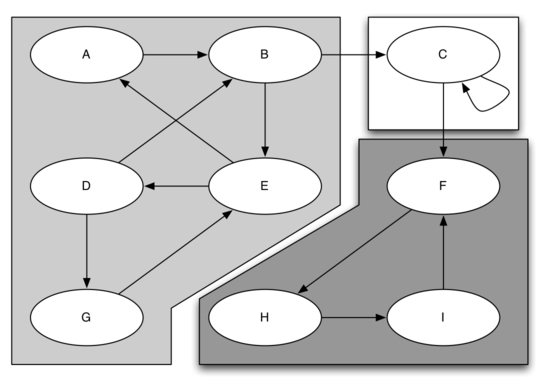
    </div>
    <div style="width: 45%;">
        <p>📉 The Reduced Graph of the Components</p>
        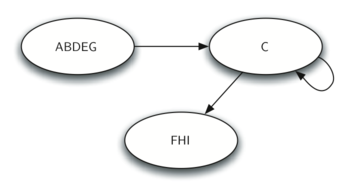
    </div>
</div>



<div style="display: flex; justify-content: space-around; align-items: flex-start; gap: 20px; font-weight: bold; text-align: center;">
    <div style="width: 45%;">
        <p>📊 A Graph G</p>
        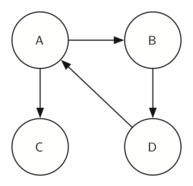
    </div>
    <div style="width: 45%;">
        <p>🔄 The Transposition of G (Gᵀ)</p>
        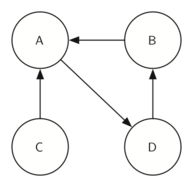
    </div>
</div>




<table style="width: 100%; border: none; text-align: center; font-weight: bold; background: transparent;">
  <!-- ROW 1: HEADERS -->
  <tr style="border: none;">
    <td style="width: 50%; border: none; padding: 10px;">🕒 Finishing Times for Graph G</td>
    <td style="width: 50%; border: none; padding: 10px;">🔄 Finishing Times for Gᵀ</td>
  </tr>
  
  <!-- ROW 1: IMAGES -->
  <tr style="border: none;">
    <td style="border: none; padding: 5px;">
      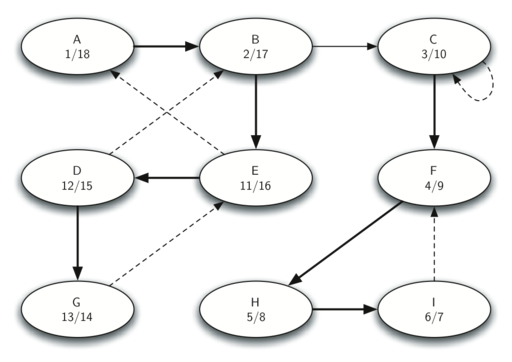
    </td>
    <td style="border: none; padding: 5px;">
      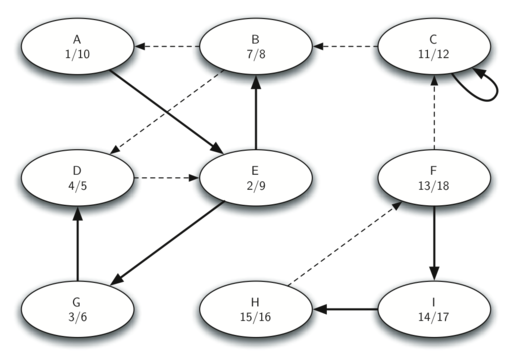
    </td>
  </tr>

  <!-- ROW 2: HEADER -->
  <tr style="border: none;">
    <td colspan="2" style="border: none; padding: 35px 10px 10px 10px;">📦 Strongly Connected Components</td>
  </tr>

  <!-- ROW 2: IMAGE -->
  <tr style="border: none;">
    <td colspan="2" style="border: none; padding: 5px;">
      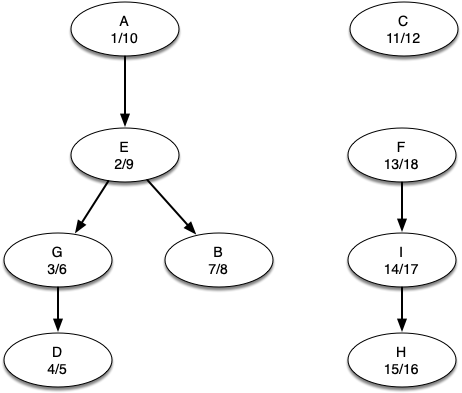
    </td>
  </tr>
</table>



#### 📦 Core Logic: Kosaraju's Transposition Trick

The Strongly Connected Components (SCC) algorithm leverages a subtle property of directed graphs: a graph \(G\) and its transpose \(G^T\) share the exact same structural components. Flipping every directed arrow backwards does not break the clusters; it just reverses the flow of traffic between them.

Kosaraju's algorithm exploits this behavior by isolating highly interconnected clusters one by one through a precise three-step sequence.

##### 1. Phase 1: Tracking the Outward Flow
We run a standard Depth-First Search (DFS) on the original graph \(G\). The goal here is to calculate the **closing times** for every single vertex. 

Sorting the vertices in decreasing order of their closing times places the nodes from the "source" components (those that can reach many other nodes) at the front of our priority list, while nodes in "sink" components (those at the end of the traffic pipeline) drop to the back.

##### 2. Phase 2: Building the Transpose Shield (\(G^T\))
We programmatically generate the transpose graph \(G^T\) by reversing the direction of every single edge pointer. 
* Any path that used to lead *out* of a component now points *into* it.
* Any path that used to lead *into* a component now acts as an exit blocker.

##### 3. Phase 3: Trapping the Search Window
We run a second DFS pass, but this time it executes on the reversed graph \(G^T\). Crucially, the master loop is forced to select unvisited nodes using our sorted priority list from Phase 1 (highest closing times first).

Because the traffic lanes are flipped, starting the search from a "source" component in \(G\) means we are actually starting at a "sink" component in \(G^T\). When `dfs_visit` dives down into the node's neighbors, it tries to escape to other clusters, but it hits the reversed arrow directions which act as dead ends. 

The recursion is trapped within the boundaries of that single component. Once the local recursive stack clears, it pops out a single, perfectly isolated Strongly Connected Component and moves to the next available white node to repeat the process.


In [1]:
# =====================================================================
# 1. GRAPH BASE ENTITIES WITH TEMPORAL TRACKING
# =====================================================================

class Vertex:
    def __init__(self, key):
        """Initializes a single node with connectivity maps and search states."""
        self.id = key
        self.neighbors = {}
        self.color = "white"       # white = unvisited, gray = discovering, black = completed
        self.previous = -1         # Predecessor mapping placeholder (-1 = no parent)
        self.discovery_time = 0   
        self.closing_time = 0     

    def set_neighbor(self, nbr, weight=0):
        """Adds a directed connection pointing from self to a neighbor vertex object."""
        self.neighbors[nbr] = weight

    def get_neighbors(self):
        """Returns neighbor objects sorted alphabetically to guarantee stable execution."""
        return sorted(self.neighbors.keys(), key=lambda v: str(v.id))

    def get_key(self):
        return self.id

    def __repr__(self):
        return f"Vertex({self.id})"


class Graph:
    def __init__(self):
        self.vertices = {}

    def set_vertex(self, key):
        if key not in self.vertices:
            self.vertices[key] = Vertex(key)
        return self.vertices[key]

    def get_vertex(self, key):
        return self.vertices.get(key, None)

    def add_edge(self, from_key, to_key, weight=0):
        if from_key not in self.vertices:
            self.set_vertex(from_key)
        if to_key not in self.vertices:
            self.set_vertex(to_key)
        self.vertices[from_key].set_neighbor(self.vertices[to_key], weight)

    def __iter__(self):
        return iter(self.vertices.values())


# =====================================================================
# 2. EXTENDED DFS & STRONGLY CONNECTED COMPONENTS ENGINE
# =====================================================================

class DFSGraph(Graph):
    def __init__(self):
        super().__init__()
        self.time = 0  # Global step counter tracking chronological ticks

    def dfs(self, order_list=None):
        """
        Modified DFS framework. If an order_list is provided, it explores 
        vertices using that specific sequence priority instead of natural iteration.
        """
        # 1. Reset all state attributes back to baseline defaults
        for vertex in self:
            vertex.color = "white"
            vertex.previous = -1
        self.time = 0
        
        # Keep track of individual component clusters during this execution sweep
        forest_trees = []

        # 2. Decide the iteration route strategy
        if order_list is not None:
            nodes_to_explore = [self.get_vertex(key) for key in order_list if self.get_vertex(key)]
        else:
            nodes_to_explore = list(self)

        # 3. Process each node
        for vertex in nodes_to_explore:
            if vertex.color == "white":
                current_tree = []
                self.dfs_visit(vertex, current_tree)
                forest_trees.append(current_tree)
                
        return forest_trees

    def dfs_visit(self, start_vertex, current_tree):
        start_vertex.color = "gray"
        self.time = self.time + 1
        start_vertex.discovery_time = self.time
        
        # Trace current node key location into the active component cluster tracker
        current_tree.append(start_vertex.get_key())
        
        for next_vertex in start_vertex.get_neighbors():
            if next_vertex.color == "white":
                next_vertex.previous = start_vertex
                self.dfs_visit(next_vertex, current_tree)
                
        start_vertex.color = "black"
        self.time = self.time + 1
        start_vertex.closing_time = self.time

    def transpose(self):
        """
        Step 2: Constructs and returns Gᵀ (the transposition graph), 
        where every directed edge arrowhead flipped exactly backwards.
        """
        g_t = DFSGraph()
        
        # Re-register all unique vertices into the new graph frame container
        for vertex in self:
            g_t.set_vertex(vertex.get_key())
            
        # Intercept edge pairs and inject them backwards: (u -> v) becomes (v -> u)
        for vertex in self:
            for neighbor in vertex.get_neighbors():
                g_t.add_edge(neighbor.get_key(), vertex.get_key())
                
        return g_t

    def compute_scc(self):
        """
        Main Orchestrator Engine for Kosaraju's SCC Algorithm:
        1. Run DFS on G to discover closing times.
        2. Compute Gᵀ.
        3. Run DFS on Gᵀ sorted by decreasing order of G's closing times.
        """
        # Step 1: Run original DFS on self (Graph G)
        self.dfs()
        
        # Extract and sort all vertices from largest closing time to smallest
        sorted_vertices = list(self.vertices.values())
        sorted_vertices.sort(key=lambda v: v.closing_time, reverse=True)
        priority_keys_sequence = [v.get_key() for v in sorted_vertices]
        
        # Step 2: Formulate the Transpose graph Gᵀ
        g_transpose = self.transpose()
        
        # Step 3 & 4: Run target DFS on Gᵀ using the custom sequence layout tracking list
        scc_forest = g_transpose.dfs(order_list=priority_keys_sequence)
        
        return scc_forest


# =====================================================================
# 3. VERIFICATION SYSTEM DRIVER RUNTIME
# =====================================================================

# Assembling a sample web mapping directory layout with 3 components (mimicking figures)
web_graph = DFSGraph()

# Component Cluster 1 (Interconnected circle web entries)
web_graph.add_edge("A", "B")
web_graph.add_edge("B", "C")
web_graph.add_edge("C", "A")

# Bridging link pointing downstream out from cluster 1 to cluster 2
web_graph.add_edge("C", "D")

# Component Cluster 2
web_graph.add_edge("D", "E")
web_graph.add_edge("E", "F")
web_graph.add_edge("F", "D")

# Bridging link pointing downstream out from cluster 2 to cluster 3
web_graph.add_edge("F", "G")

# Component Cluster 3 (Isolated sink entries)
web_graph.add_edge("G", "H")
web_graph.add_edge("H", "G")


print("=====================================================================")
print("🌐 EXECUTING STRONGLY CONNECTED COMPONENTS (SCC) DISCOVERY")
print("=====================================================================\n")

# Run Kosaraju's calculation pipeline
extracted_components = web_graph.compute_scc()

print("🏁 IDENTIFIED COMPONENT CLUSTER GROUPS:")
print("-" * 65)
for index, component in enumerate(extracted_components, 1):
    print(f" 📦 Component Set #{index:02d} -> Highly Linked Web Pages: {component}")
print("-" * 65)


🌐 EXECUTING STRONGLY CONNECTED COMPONENTS (SCC) DISCOVERY

🏁 IDENTIFIED COMPONENT CLUSTER GROUPS:
-----------------------------------------------------------------
 📦 Component Set #01 -> Highly Linked Web Pages: ['A', 'C', 'B']
 📦 Component Set #02 -> Highly Linked Web Pages: ['D', 'F', 'E']
 📦 Component Set #03 -> Highly Linked Web Pages: ['G', 'H']
-----------------------------------------------------------------


#### 📉 Graph Condensation: The Reduced Graph Pipeline

Once the strongly connected components of a directed graph are isolated, we can run a structural transformation process known as **graph condensation** or **graph reduction**. 

This pipeline groups highly interconnected operational elements together, allowing us to evaluate large data configurations from a higher-level perspective.

##### 1. Defining the Transformation Dynamics
To turn the discovered component groups into a single structured pipeline network:
1. **Meta-Node Convergence:** Every strongly connected component set (e.g., `['A', 'B', 'C']`) collapses into a single unified vertex capsule, which we can label using collection sets like `{A,B,C}`.
2. **Intra-Component Edge Elimination:** Any directed internal edges pointing between nodes within the *same* component are deleted entirely. They represent internal looping states and are irrelevant to macro-level structural navigation dependencies.
3. **Inter-Component Edge Consolidation:** If an edge in the original graph links an item in Component 1 to an item in Component 2, a directed edge is built linking Meta-Node 1 straight to Meta-Node 2.

##### 2. The Direct Acyclic Graph (DAG) Guarantee
The most powerful property of a Reduced Graph is a guaranteed mathematical constraint: **The resulting compressed graph is always a Directed Acyclic Graph (DAG).**

By collapsing all cyclic loops and strongly connected components down into closed meta-nodes, **all feedback loops are eliminated**. This means you can run a **Topological Sort** across the resulting reduced graph framework, allowing you to sequence and organize dependencies across large, interconnected structures that initially contained loops!


In [2]:
# =====================================================================
# 1. CORE GRAPH STRUCTS FOR COMPRESSOR DATA ENGINE
# =====================================================================

class Vertex:
    def __init__(self, key):
        self.id = key
        self.neighbors = {}
        self.color = "white"       
        self.previous = -1         
        self.discovery_time = 0   
        self.closing_time = 0     

    def set_neighbor(self, nbr, weight=0):
        self.neighbors[nbr] = weight

    def get_neighbors(self):
        return sorted(self.neighbors.keys(), key=lambda v: str(v.id))

    def get_key(self):
        return self.id

    def __repr__(self):
        return f"Vertex({self.id})"


class Graph:
    def __init__(self):
        self.vertices = {}

    def set_vertex(self, key):
        if key not in self.vertices:
            self.vertices[key] = Vertex(key)
        return self.vertices[key]

    def get_vertex(self, key):
        return self.vertices.get(key, None)

    def add_edge(self, from_key, to_key, weight=0):
        if from_key not in self.vertices:
            self.set_vertex(from_key)
        if to_key not in self.vertices:
            self.set_vertex(to_key)
        self.vertices[from_key].set_neighbor(self.vertices[to_key], weight)

    def __iter__(self):
        return iter(self.vertices.values())


# =====================================================================
# 2. EXTENDED DFS & SCC DISCOVERY MODULES
# =====================================================================

class DFSGraph(Graph):
    def __init__(self):
        super().__init__()
        self.time = 0  

    def dfs(self, order_list=None):
        for vertex in self:
            vertex.color = "white"
            vertex.previous = -1
        self.time = 0
        forest_trees = []

        if order_list is not None:
            nodes_to_explore = [self.get_vertex(key) for key in order_list if self.get_vertex(key)]
        else:
            nodes_to_explore = list(self)

        for vertex in nodes_to_explore:
            if vertex.color == "white":
                current_tree = []
                self.dfs_visit(vertex, current_tree)
                forest_trees.append(current_tree)
                
        return forest_trees

    def dfs_visit(self, start_vertex, current_tree):
        start_vertex.color = "gray"
        self.time = self.time + 1
        start_vertex.discovery_time = self.time
        current_tree.append(start_vertex.get_key())
        
        for next_vertex in start_vertex.get_neighbors():
            if next_vertex.color == "white":
                next_vertex.previous = start_vertex
                self.dfs_visit(next_vertex, current_tree)
                
        start_vertex.color = "black"
        self.time = self.time + 1
        start_vertex.closing_time = self.time

    def transpose(self):
        g_t = DFSGraph()
        for vertex in self:
            g_t.set_vertex(vertex.get_key())
        for vertex in self:
            for neighbor in vertex.get_neighbors():
                g_t.add_edge(neighbor.get_key(), vertex.get_key())
        return g_t

    def compute_scc(self):
        self.dfs()
        sorted_vertices = list(self.vertices.values())
        sorted_vertices.sort(key=lambda v: v.closing_time, reverse=True)
        priority_keys_sequence = [v.get_key() for v in sorted_vertices]
        
        g_transpose = self.transpose()
        scc_forest = g_transpose.dfs(order_list=priority_keys_sequence)
        return scc_forest


# =====================================================================
# 3. THE GRAPH COMPRESSOR ENGINE (Building the Reduced Graph)
# =====================================================================

def compress_graph(original_graph, components_list):
    """
    Transforms a complex graph into a simplified 'Reduced Graph' DAG.
    Collapses each strongly connected component list cluster into a single meta-node.
    """
    reduced_g = Graph()
    node_to_comp_id = {}
    comp_id_to_name = {}

    # Step 1: Create naming aliases and index mappings for the meta-nodes
    for index, component in enumerate(components_list, 1):
        # Sort internal components alphabetically for deterministic string naming
        sorted_comp = sorted(component)
        meta_node_name = "{" + ",".join(sorted_comp) + "}"
        
        comp_id_to_name[index] = meta_node_name
        reduced_g.set_vertex(meta_node_name)
        
        # Build dictionary map to track which original node belongs to which component ID
        for node_key in component:
            node_to_comp_id[node_key] = index

    # Step 2: Establish the directed edges connecting the meta-nodes
    for vertex in original_graph:
        from_node_key = vertex.get_key()
        from_comp_id = node_to_comp_id[from_node_key]
        from_meta_name = comp_id_to_name[from_comp_id]
        
        for neighbor in vertex.get_neighbors():
            to_node_key = neighbor.get_key()
            to_comp_id = node_to_comp_id[to_node_key]
            to_meta_name = comp_id_to_name[to_comp_id]
            
            # Add edge if the connection links two DIFFERENT strongly connected components
            if from_comp_id != to_comp_id:
                reduced_g.add_edge(from_meta_name, to_meta_name)
                
    return reduced_g


# =====================================================================
# 4. VERIFICATION SYSTEM DRIVER RUNTIME
# =====================================================================

# Build our initial uncompressed web graph framework instance
web_graph = DFSGraph()

web_graph.add_edge("A", "B")
web_graph.add_edge("B", "C")
web_graph.add_edge("C", "A")  # Component 1 Loop Complete

web_graph.add_edge("C", "D")  # Inter-component bridge

web_graph.add_edge("D", "E")
web_graph.add_edge("E", "F")
web_graph.add_edge("F", "D")  # Component 2 Loop Complete

web_graph.add_edge("F", "G")  # Inter-component bridge

web_graph.add_edge("G", "H")
web_graph.add_edge("H", "G")  # Component 3 Loop Complete


# Execute Kosaraju's algorithm pipeline to discover clusters
scc_clusters = web_graph.compute_scc()

# Compress the entire graph structure into the simplified design view layout
reduced_web_graph = compress_graph(web_graph, scc_clusters)


print("=====================================================================")
print("📉 VERIFYING THE REDUCED GRAPH INFRASTRUCTURE")
print("=====================================================================\n")

print("1. Extracted Meta-Nodes (Simplified View Vertices Inventory):")
print("-" * 65)
for meta_vertex in reduced_web_graph:
    print(f" 🟢 Active Meta-Node Element: {meta_vertex.get_key()}")
print("-" * 65)

print("\n2. Operational Directed Edge Connections Linking Meta-Nodes:")
print("-" * 65)
for meta_vertex in reduced_web_graph:
    for neighbor in meta_vertex.get_neighbors():
        print(f" 🔥 Directed Path: {meta_vertex.get_key()} ──► {neighbor.get_key()}")
print("-" * 65)


📉 VERIFYING THE REDUCED GRAPH INFRASTRUCTURE

1. Extracted Meta-Nodes (Simplified View Vertices Inventory):
-----------------------------------------------------------------
 🟢 Active Meta-Node Element: {A,B,C}
 🟢 Active Meta-Node Element: {D,E,F}
 🟢 Active Meta-Node Element: {G,H}
-----------------------------------------------------------------

2. Operational Directed Edge Connections Linking Meta-Nodes:
-----------------------------------------------------------------
 🔥 Directed Path: {A,B,C} ──► {D,E,F}
 🔥 Directed Path: {D,E,F} ──► {G,H}
-----------------------------------------------------------------
